In [25]:
import numpy as np
import matplotlib.pyplot as plt

In [26]:
def regionQuery(D, P, eps):

    # khởi tạo danh sách
    neighbors = []

    # duyệt qua tất cả các điểm
    for Pn in range(len(D)):

        # Tính khoảng cách Euclidean
        distance = np.linalg.norm(D[P] - D[Pn])

        # nếu distance < eps thì thêm vào danh sách lân cận
        if distance < eps:
            neighbors.append(Pn)

    # trả về danh sách chỉ số 
    return neighbors

In [27]:
def growCluster(D, labels, P, NeighborPts, C, eps, MinPts):

    # gán nhãn điểm P vào cụm C
    labels[P] = C

    # khởi tạo vị trí
    i = 0

    # tiếp tục duyệt khi vẫn còn điểm trong danh sách
    while i < len(NeighborPts):

        # lấy chỉ số điểm lân cận tiếp theo
        Pn = NeighborPts[i]

        # nếu điểm đang được đánh dấu là nhiễu
        if labels[Pn] == -1:

            # gán điểm nhiễu vào cụm hiện tại
            labels[Pn] = C

        # nếu điểm chưa thuộc cụm nào
        elif labels[Pn] == 0:

            # gán điểm vào cụm hiện tại
            labels[Pn] = C

            # tìm các điểm lân cận của điểm vừa xét
            PnNeighborPts = regionQuery(D, Pn, eps)

            # kiểm tra điểm vừa xét có phải điểm lõi hay không
            if len(PnNeighborPts) >= MinPts:

                # nếu là điểm lõi, thêm các điểm lân cận vào danh sách
                NeighborPts = NeighborPts + PnNeighborPts

        # chuyển sang điểm tiếp theo
        i += 1

In [28]:
def MyDBSCAN(D, eps, MinPts):

    # khởi tạo nhãn cho tất cả điểm bằng 0
    labels = [0] * len(D)

    # khởi tạo mã cụm
    C = 0

    # duyệt qua tập dữ liệu
    for P in range(len(D)):

        # bỏ qua điểm đã được xét hoặc đã thuộc cụm
        if labels[P] != 0:
            continue

        # tìm các điểm lân cận của điểm hiện tại
        NeighborPts = regionQuery(D, P, eps)

        # nếu số điểm lân cận nhỏ hơn MinPts
        if len(NeighborPts) < MinPts:

            # đánh dấu điểm hiện tại là nhiễu
            labels[P] = -1

        else:

            # tạo một cụm mới
            C += 1

            # mở rộng cụm từ điểm hiện tại
            growCluster(
                D,
                labels,
                P,
                NeighborPts,
                C,
                eps,
                MinPts
            )

    return labels

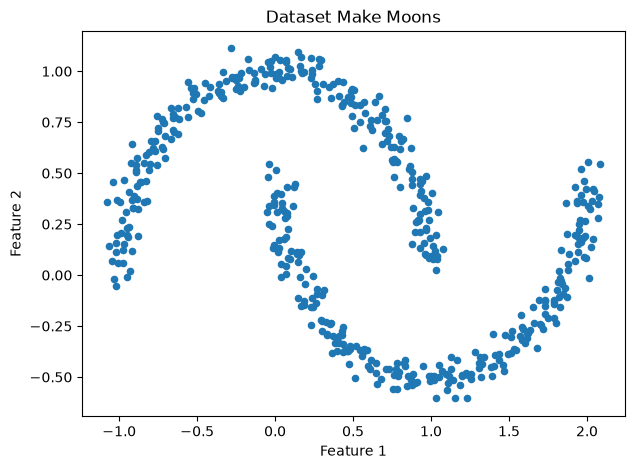

In [29]:
from sklearn.datasets import make_moons#dataset makemoons

# tạo dataset 500 điểm với ít nhiễu
X, y_true = make_moons(
    n_samples=500,
    noise=0.05,
    random_state=42
)

# hiển thị dữ liệu ban đầu
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=20)

plt.title("Dataset Make Moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [30]:
# thiết lập các tham số DBSCAN
eps = 0.2
MinPts = 5

# thực hiện gom cụm bằng thuật toán tự cài đặt
labels_custom = MyDBSCAN(X, eps, MinPts)

# chuyển result thành mảng NumPy
labels_custom = np.array(labels_custom)

# xác định số cụm,không tính điểm nhiễu
n_clusters_custom = len(set(labels_custom) - {-1})

# đếm số điểm nhiễu
n_noise_custom = np.sum(labels_custom == -1)

print("DBSCAN")
print("Number of clusters:", n_clusters_custom)
print("Number of noise points:", n_noise_custom)

DBSCAN
Number of clusters: 2
Number of noise points: 0


In [31]:
from sklearn.cluster import DBSCAN

# khởi tạo DBSCAN với cùng tham số
dbscan = DBSCAN(
    eps=eps,
    min_samples=MinPts
)

# thực hiện gom cụm
labels_sklearn = dbscan.fit_predict(X)

# xác định số cụm, không tính điểm nhiễu
n_clusters_sklearn = len(set(labels_sklearn) - {-1})

# đếm số điểm nhiễu
n_noise_sklearn = np.sum(labels_sklearn == -1)

# in kết quả
print("DBSCAN Scikit-learn")
print("Number of clusters:", n_clusters_sklearn)
print("Number of noise points:", n_noise_sklearn)

DBSCAN Scikit-learn
Number of clusters: 2
Number of noise points: 0


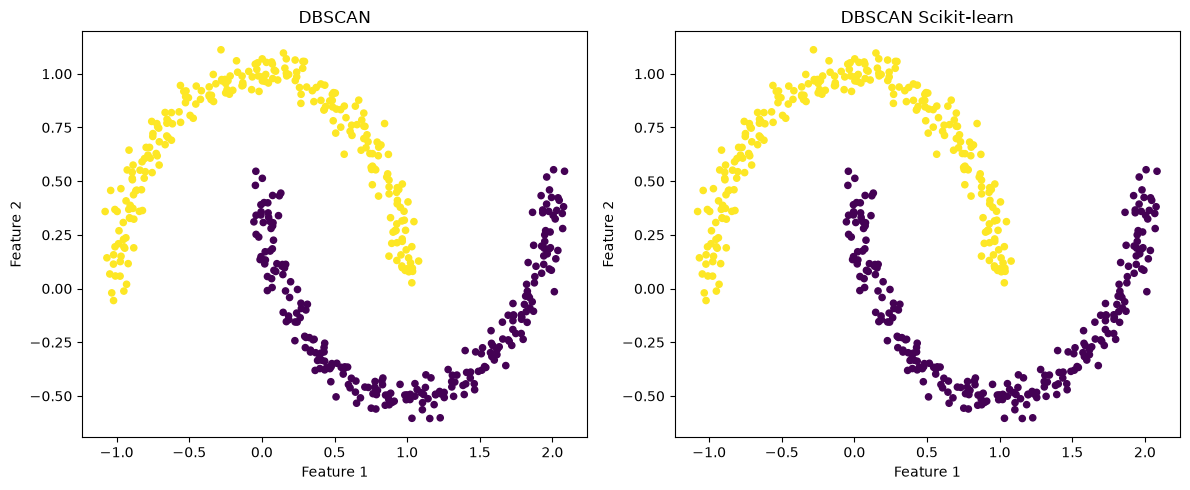

In [32]:
# tạo hai biểu đồ để so sánh
plt.figure(figsize=(12, 5))

# biểu đồ kết quả DBSCAN tự cài đặt
plt.subplot(1, 2, 1)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels_custom,
    cmap="viridis",
    s=20
)

plt.title("DBSCAN")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# biểu đồ kết quả DBSCAN Scikit-learn
plt.subplot(1, 2, 2)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels_sklearn,
    cmap="viridis",
    s=20
)

plt.title("DBSCAN Scikit-learn")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# điều chỉnh khoảng cách giữa hai biểu đồ
plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import adjusted_rand_score

# tính chỉ số ARI giữa hai kết quả phân cụm
ari = adjusted_rand_score(
    labels_custom,
    labels_sklearn
)

# hiển thị kết quả
print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 1.0
